In [ ]:
# ==============================================================================
# BƯỚC 1: KHỞI TẠO HỆ THỐNG & FORWARD MODEL ĐỊNH LUẬT BIOT-SAVART CHO 3 CUỘN THU ĐƠN TRỰC GIAO
# ==============================================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d.art3d import Poly3DCollection
from scipy.optimize import least_squares
import copy

def rotx(angle_deg):
    rad = np.radians(angle_deg)
    return np.array([[1, 0, 0], [0, np.cos(rad), -np.sin(rad)], [0, np.sin(rad),  np.cos(rad)]])

def roty(angle_deg):
    rad = np.radians(angle_deg)
    return np.array([[ np.cos(rad), 0, np.sin(rad)], [0, 1, 0], [-np.sin(rad), 0, np.cos(rad)]])

def rotz(angle_deg):
    rad = np.radians(angle_deg)
    return np.array([[np.cos(rad), -np.sin(rad), 0], [np.sin(rad),  np.cos(rad), 0], [0, 0, 1]])

def orthogonal_rx_axes(mis3, ideal_axes):
    # 3 cuộn RX đơn trực giao: cả bộ 3 trục quay cứng cùng nhau bởi ma trận lệch lắp đặt
    # R_mis = Rz(gamma) @ Ry(beta) @ Rx(alpha)  ->  luôn giữ tính trực giao giữa 3 trục
    R_mis = rotz(mis3[2]) @ roty(mis3[1]) @ rotx(mis3[0])
    return (R_mis @ ideal_axes.T).T

class SystemConfiguration:
    def __init__(self):
        # Thông số cuộn phát (TX)
        self.Ntx = 195
        self.R = 0.06                               # Bán kính khởi tạo vòng dây TX = 60 mm (sẽ được hiệu chuẩn ở Bước 3)
        self.I = np.array([1.0, 1.0, 1.0])
        self.f = np.array([5053.0, 6911.0, 5932.0])
        self.M_seg = 72                             # Số đoạn tích phân đường Biot-Savart

        # Ma trận thông số ban đầu của 3 TX (X [m], Y [m], Z [m], Roll, Pitch, Yaw [deg])
        # Bộ dữ liệu 3Tx-3Rx (gridnorot): giá trị xấp xỉ sau calib trong README, gốc tọa độ = gốc robot, IN MM
        self.TX_positions = np.array([
            [-102.05, 460.84, 89.86, 15, 0, 0], # TX1
            [-26.68, 346.91, 82.74, 0, -15, -30], # TX2
            [-161.34, 335.03, 84.16, 0, 15, 30]  # TX3
        ]).T
        self.system_center = [-93.81, 378.13, 66.35]

        # Thông số 3 cuộn thu ĐƠN (RX1, RX2, RX3) - không vi sai
        self.Nrx = 100
        self.AK = np.array([np.pi * 4.0, 6.79 * 4.0, 6.0 * 6.87]) * 1e-6
        self.circuit_gain = 1e5
        self.K_theoretical = self.Nrx * self.AK * self.circuit_gain
        self.mu0 = 4 * np.pi * 1e-7

        # Trục thiết kế của 3 cuộn RX trực giao (X, Z, Y) trong khung RX và góc lệch lắp đặt (deg)
        self.rx_axes_ideal = np.array([[1.0, 0.0, 0.0], [0.0, 0.0, 1.0], [0.0, 1.0, 0.0]])
        self.rx_mis = np.zeros(3)
        self.rx_axes = orthogonal_rx_axes(self.rx_mis, self.rx_axes_ideal)

sys_config = SystemConfiguration()
TX_positions_pre_calib = sys_config.TX_positions.copy()
R_pre_calib = sys_config.R

def _R_batch(poses):
    r, pt, y = np.radians(poses[:, 3]), np.radians(poses[:, 4]), np.radians(poses[:, 5])
    cr, sr, cp, sp, cy, sy = np.cos(r), np.sin(r), np.cos(pt), np.sin(pt), np.cos(y), np.sin(y)
    R = np.zeros((len(poses), 3, 3))
    R[:, 0, 0] = cy*cp; R[:, 0, 1] = cy*sp*sr - sy*cr; R[:, 0, 2] = cy*sp*cr + sy*sr
    R[:, 1, 0] = sy*cp; R[:, 1, 1] = sy*sp*sr + cy*cr; R[:, 1, 2] = sy*sp*cr - cy*sr
    R[:, 2, 0] = -sp;   R[:, 2, 1] = cp*sr;            R[:, 2, 2] = cp*cr
    return R

def B_biot_savart_batch(P, sys, tx_idx):
    c_tx = sys.TX_positions[0:3, tx_idx]
    a, b, g = sys.TX_positions[3:6, tx_idx]
    Rtx = rotz(g) @ roty(b) @ rotx(a)
    phi = np.linspace(0.0, 2.0 * np.pi, sys.M_seg, endpoint=False)
    dphi = 2.0 * np.pi / sys.M_seg
    R = sys.R[tx_idx] * 1000 if np.ndim(sys.R) > 0 else sys.R * 1000
    l_loc  = np.column_stack([R * np.cos(phi), R * np.sin(phi), np.zeros_like(phi)])
    dl_loc = np.column_stack([-R * np.sin(phi) * dphi, R * np.cos(phi) * dphi, np.zeros_like(phi)])
    l_world  = c_tx + (l_loc @ Rtx.T)
    dl_world = dl_loc @ Rtx.T
    diff = P[:, None, :] - l_world[None, :, :]
    dist2 = np.sum(diff**2, axis=2)
    dist3 = dist2 * np.sqrt(dist2)
    cross_prod = np.cross(dl_world[None, :, :], diff)
    pref = (sys.mu0 * sys.Ntx * sys.I[tx_idx]) / (4.0 * np.pi)
    return pref * np.sum(cross_prod / dist3[:, :, None], axis=1)

def emf_single_coil_batch(poses, sys, rx_idx, tx_idx):
    # Mô hình Cuộn Thu Đơn (Faraday, cuộn nhỏ): EMF_raw = 2*pi*f * | B(p) . n |
    n_world = _R_batch(poses) @ sys.rx_axes[rx_idx]
    B = B_biot_savart_batch(poses[:, 0:3], sys, tx_idx)
    flux = np.einsum('ij,ij->i', B, n_world)
    return 2.0 * np.pi * sys.f[tx_idx] * np.abs(flux)

def euler_to_quat_zyx(ex_deg, ey_deg, ez_deg):
    """Converts Z-Y-X Euler angles (degrees) to a Quaternion [w, x, y, z]."""
    hx = np.radians(ex_deg / 2.0)
    hy = np.radians(ey_deg / 2.0)
    hz = np.radians(ez_deg / 2.0)

    cx, sx = np.cos(hx), np.sin(hx)
    cy, sy = np.cos(hy), np.sin(hy)
    cz, sz = np.cos(hz), np.sin(hz)

    w = cx * cy * cz + sx * sy * sz
    x = sx * cy * cz - cx * sy * sz
    y = cx * sy * cz + sx * cy * sz
    z = cx * cy * sz - sx * sy * cz
    return np.array([w, x, y, z])

def quat_inv(q):
    """Computes the inverse of a quaternion [w, x, y, z]."""
    w, x, y, z = q
    norm_sq = w**2 + x**2 + y**2 + z**2
    return np.array([w, -x, -y, -z]) / norm_sq

def quat_mul(q1, q2):
    """Multiplies two quaternions q1 * q2."""
    w1, x1, y1, z1 = q1
    w2, x2, y2, z2 = q2
    w = w1*w2 - x1*x2 - y1*y2 - z1*z2
    x = w1*x2 + x1*w2 + y1*z2 - z1*y2
    y = w1*y2 - x1*z2 + y1*w2 + z1*x2
    z = w1*z2 + x1*y2 - y1*x2 + z1*w2
    return np.array([w, x, y, z])

def quat_to_euler_zyx(q):
    """Converts a Quaternion [w, x, y, z] back to Z-Y-X Euler angles (degrees)."""
    w, x, y, z = q

    # Pitch (Y)
    sin_y = 2.0 * (w * y - z * x)
    
    # Check for vectorized numpy array processing vs scalar processing
    if np.isscalar(sin_y):
        if sin_y >= 1.0:
            py = np.pi / 2.0
        elif sin_y <= -1.0:
            py = -np.pi / 2.0
        else:
            py = np.arcsin(sin_y)
    else:
        sin_y = np.clip(sin_y, -1.0, 1.0)
        py = np.arcsin(sin_y)

    # Roll (X)
    roll = np.arctan2(2.0 * (w * x + y * z), 1.0 - 2.0 * (x**2 + y**2))

    # Yaw (Z)
    yaw = np.arctan2(2.0 * (w * z + x * y), 1.0 - 2.0 * (y**2 + z**2))

    return np.degrees(roll), np.degrees(py), np.degrees(yaw)

def get_true_relative_tilt(ex_curr, ey_curr, ez_curr, ex_init, ey_init, ez_init):
    """
    Strips the base offset using Pre-multiplication matching the MATLAB generator,
    returning the true isolated tilt angles (Ex, Ey, Ez).
    """
    q_curr = euler_to_quat_zyx(ex_curr, ey_curr, ez_curr)
    q_init = euler_to_quat_zyx(ex_init, ey_init, ez_init)

    # MATCH GENERATOR: Q_curr = Q_tilt * Q_init  =>  Q_tilt = Q_curr * Q_init_inv
    q_init_inv = quat_inv(q_init)
    q_tilt = quat_mul(q_curr, q_init_inv)

    if np.isscalar(q_tilt[0]):
        if q_tilt[0] < 0:
            q_tilt = -q_tilt
    else:
        q_tilt = np.where(q_tilt[0] < 0, -q_tilt, q_tilt)

    true_ex, true_ey, true_ez = quat_to_euler_zyx(q_tilt)
    return true_ex, true_ey, true_ez

print("Đã khởi tạo cấu hình hệ thống & Mô hình 3 Cuộn Thu Đơn Trực Giao + Biot-Savart (có tham số R hiệu chuẩn) thành công.")

Đã khởi tạo cấu hình hệ thống & Mô hình 3 Cuộn Thu Đơn Trực Giao + Biot-Savart (có tham số R hiệu chuẩn) thành công.


Files already exist. Skipping generation. Set FORCE_GENERATE = True to overwrite.
Original shape: (12000, 15)
Averaged shape: (1200, 15)
Std Dev shape:  (1200, 15)

--- POSE WITH LOWEST EMF STD (Block Index 711) ---
Mean EMF: [  0.2914  13.6599  36.2647  65.0053 182.0551  41.8128  85.1306 130.2957
  11.761 ]
STD EMF:  [0.045948 0.057944 0.036467 0.033723 0.033848 0.051557 0.041147 0.038572
 0.025491]

--- POSE WITH HIGHEST EMF STD (Block Index 900) ---
Mean EMF: [  2.707  116.4996  72.6736   9.0261 496.8559  32.6442 103.8122 104.6095
 113.9642]
STD EMF:  [ 0.33582   5.008568  0.885525  2.702607 18.47096   3.299308  0.644303
  2.103777  2.271559]



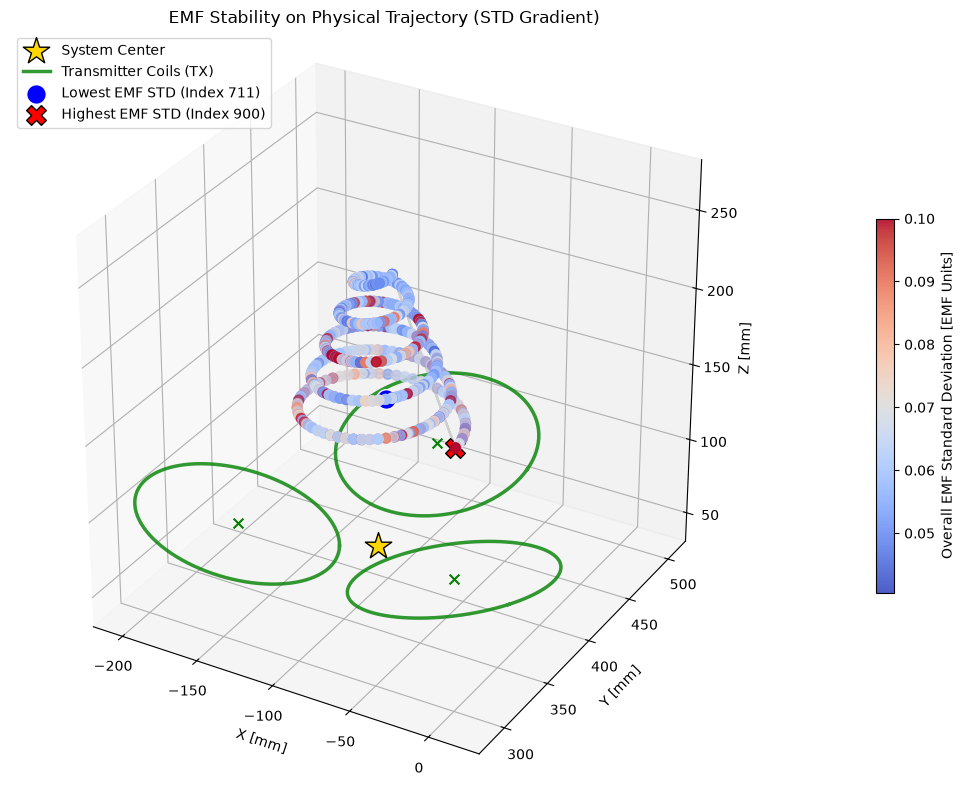

In [24]:
# ==============================================================================
# BƯỚC 1.5.1: XỬ LÝ FILE DỮ LIỆU RAW (9 cột EMF + 6 cột DOF)
# ==============================================================================

# 1. Load the original raw data
trajectory = 'cone'
file_path = trajectory + '_data.csv'
data = pd.read_csv(file_path, header=None).values

# 2. Remove Rx angle offset
EX_INIT, EY_INIT, EZ_INIT = 179.91, 0.01, 66.28

data[:, 12:15] = np.array(get_true_relative_tilt(
    data[:, 12], data[:, 13], data[:, 14],
    EX_INIT, EY_INIT, EZ_INIT
)).T

# 3. Determine N_samples and reshape
N_MEASUREMENTS = 10
block_size = N_MEASUREMENTS
N_samples = data.shape[0] // block_size

truncated_data = data[:N_samples * block_size, :]
reshaped_data = truncated_data.reshape((N_samples, block_size, 15))

# 4. Calculate Mean and Standard Deviation
averaged_data = np.mean(reshaped_data, axis=1)
std_data = np.std(reshaped_data, axis=1)

# 5. Conditionally save the results
FORCE_GENERATE = False  # Change to True to overwrite existing files

avg_filename = f'avg_{trajectory}_data.csv'
std_filename = f'std_{trajectory}_data.csv'

if FORCE_GENERATE or not (os.path.exists(avg_filename) and os.path.exists(std_filename)):
    pd.DataFrame(averaged_data).to_csv(avg_filename, index=False, header=False)
    pd.DataFrame(std_data).to_csv(std_filename, index=False, header=False)
    print(f"Files saved: {avg_filename}, {std_filename}")
else:
    print(f"Files already exist. Skipping generation. Set FORCE_GENERATE = True to overwrite.")

print(f"Original shape: {data.shape}")
print(f"Averaged shape: {averaged_data.shape}")
print(f"Std Dev shape:  {std_data.shape}\n")

# ==============================================================================
# BƯỚC 1.5.2: THỐNG KÊ LOWEST / HIGHEST EMF STD
# ==============================================================================

# 1. Calculate overall STD for the 9 EMF channels (Columns 0 to 8)
emf_overall_std = np.mean(std_data[:, 0:9], axis=1)

# 2. Find the indices of the lowest and highest overall EMF STD
min_idx = np.argmin(emf_overall_std)
max_idx = np.argmax(emf_overall_std)

# 3. Print the results for EMF
print(f"--- POSE WITH LOWEST EMF STD (Block Index {min_idx}) ---")
print(f"Mean EMF: {np.round(averaged_data[min_idx, 0:9], 4)}")
print(f"STD EMF:  {np.round(std_data[min_idx, 0:9], 6)}\n")

print(f"--- POSE WITH HIGHEST EMF STD (Block Index {max_idx}) ---")
print(f"Mean EMF: {np.round(averaged_data[max_idx, 0:9], 4)}")
print(f"STD EMF:  {np.round(std_data[max_idx, 0:9], 6)}\n")

# 4. Show the trajectory in a 3D figure with a STD color gradient
x_coords = averaged_data[:, 9]
y_coords = averaged_data[:, 10]
z_coords = averaged_data[:, 11]

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')

# Plot a faint line to show the chronological path of the trajectory
ax.plot(x_coords, y_coords, z_coords, color='gray', linestyle='-', alpha=0.3, zorder=1)

# Scatter plot using EMF STD for the gradient
scatter = ax.scatter(x_coords, y_coords, z_coords, 
                     c=emf_overall_std, cmap='coolwarm',
                     vmax=0.1,
                     s=50, alpha=0.9, zorder=2)

# Add a color bar mapping the colors to the EMF STD values
cbar = fig.colorbar(scatter, ax=ax, shrink=0.5, pad=0.1)
cbar.set_label('Overall EMF Standard Deviation [EMF Units]')

# Highlight the System Center
cx, cy, cz = sys_config.system_center
# cx *= 1000
# cy *= 1000
# cz *= 1000
ax.scatter(cx, cy, cz, 
           color='gold', s=400, marker='*', edgecolors='black', 
           label='System Center', zorder=6)

# ==============================================================================
# DRAW PHYSICAL SHAPES OF TX COILS
# ==============================================================================
tx_perimeters_x, tx_perimeters_y, tx_perimeters_z = [], [], []

for tx_idx in range(3):
    # Trích xuất tọa độ center và góc Euler (đã tính bằng mét/độ)
    c_tx = sys_config.TX_positions[0:3, tx_idx]
    a, b, g = sys_config.TX_positions[3:6, tx_idx]
    
    # Tạo ma trận xoay (Roll -> Pitch -> Yaw)
    Rtx = rotz(g) @ roty(b) @ rotx(a)
    
    # Tạo các điểm trên vòng tròn 2D cục bộ (100 điểm để đường tròn mượt)
    phi = np.linspace(0.0, 2.0 * np.pi, 100)
    R_tx = sys_config.R * 1000 # Đổi bán kính sang mm
    
    # Tọa độ cục bộ [X, Y, Z] (Hình tròn nằm trên mặt phẳng XY, Z=0)
    l_loc = np.column_stack([R_tx * np.cos(phi), R_tx * np.sin(phi), np.zeros_like(phi)])
    
    # Biến đổi sang hệ tọa độ thế giới (nhân ma trận xoay + tịnh tiến)
    c_tx_mm = c_tx
    l_world = c_tx_mm + (l_loc @ Rtx.T)
    
    # Lưu lại để tính bounding box
    tx_perimeters_x.extend(l_world[:, 0])
    tx_perimeters_y.extend(l_world[:, 1])
    tx_perimeters_z.extend(l_world[:, 2])
    
    # Vẽ cuộn dây TX (vòng tròn) và điểm tâm
    label = 'Transmitter Coils (TX)' if tx_idx == 0 else None
    ax.plot(l_world[:, 0], l_world[:, 1], l_world[:, 2], color='green', linewidth=2.5, alpha=0.8, zorder=6, label=label)
    ax.scatter(c_tx_mm[0], c_tx_mm[1], c_tx_mm[2], color='green', s=50, marker='x', zorder=6)

# ==============================================================================

# Highlight lowest and highest EMF STD locations
ax.scatter(x_coords[min_idx], y_coords[min_idx], z_coords[min_idx], 
           color='blue', s=200, marker='o', edgecolors='white', 
           label=f'Lowest EMF STD (Index {min_idx})', zorder=5)

ax.scatter(x_coords[max_idx], y_coords[max_idx], z_coords[max_idx], 
           color='red', s=200, marker='X', edgecolors='black', 
           label=f'Highest EMF STD (Index {max_idx})', zorder=5)

ax.set_xlabel('X [mm]')
ax.set_ylabel('Y [mm]')
ax.set_zlabel('Z [mm]')
ax.set_title('EMF Stability on Physical Trajectory (STD Gradient)')
ax.legend(loc='upper left')

# --- FIX 3D DISTORTION (1:1:1 PHYSICAL ASPECT RATIO) ---
# Sử dụng toàn bộ điểm viền của các cuộn TX để đảm bảo không bị cắt rìa
all_x = np.concatenate([x_coords, [cx], tx_perimeters_x])
all_y = np.concatenate([y_coords, [cy], tx_perimeters_y])
all_z = np.concatenate([z_coords, [cz], tx_perimeters_z])

max_range = np.array([
    all_x.max() - all_x.min(), 
    all_y.max() - all_y.min(), 
    all_z.max() - all_z.min()
]).max() / 2.0

mid_x = (all_x.max() + all_x.min()) * 0.5
mid_y = (all_y.max() + all_y.min()) * 0.5
mid_z = (all_z.max() + all_z.min()) * 0.5

ax.set_xlim(mid_x - max_range, mid_x + max_range)
ax.set_ylim(mid_y - max_range, mid_y + max_range)
ax.set_zlim(mid_z - max_range, mid_z + max_range)

if hasattr(ax, 'set_box_aspect'):
    ax.set_box_aspect((1, 1, 1))

plt.tight_layout()
plt.show()

In [ ]:
# ==============================================================================
# BƯỚC 2: TẢI DỮ LIỆU THỰC NGHIỆM TỪ FILE DUY NHẤT (9 cột EMF + 6 cột DOF)
# ==============================================================================

# data_dir = 'repo_temp/3-Tx---3-Rx-EMF-and-Position-Data-main/'
data_filename = 'avg_' + trajectory + '_data.csv'   

# Đọc file duy nhất (15 cột)
data = pd.read_csv(data_filename, header=None).values
N_samples = data.shape[0]

# Tách dữ liệu: 9 cột đầu là EMF, 6 cột sau là Pose
emf_measured = data[:, 0:9]  # Cột 0-8
pos_ref = data[:, 9:15]      # Cột 9-14: X, Y, Z [m], Ang_X, Ang_Y, Ang_Z [deg]

# Khởi tạo ma trận pose tham chiếu
gt_pose = np.zeros((N_samples, 6))
gt_pose[:, 0:3] = pos_ref[:, 0:3]
gt_pose[:, 3:] = pos_ref[:, 3:]

print(f"Đã tải thành công {N_samples} mẫu từ '{data_filename}'.")
print(f"Offset góc lắp RX đã loại bỏ: Ang_X = EX_INIT°, Ang_Y = EY_INIT°, Ang_Z = EZ_INIT°")

Đã tải thành công 1200 mẫu từ 'avg_cone_data.csv'.
Offset góc lắp RX đã loại bỏ: Ang_X = 0.000°, Ang_Y = 0.000°, Ang_Z = -0.000°


In [ ]:
# ==============================================================================
# BƯỚC 3: HIỆU CHUẨN ĐỒNG THỜI (LỆCH GÓC LẮP BỘ 3 CUỘN RX ĐƠN TRỰC GIAO + TỌA ĐỘ TX + BÁN KÍNH VÒNG DÂY R)
# ==============================================================================
print("Đang chạy Hiệu chuẩn Thống nhất (Orthogonal Single-coil RX + TX Pose + Coil Radius R) với Biot-Savart Law...")

# Vector tham số (19 biến):
#   - x[0:3]   : 3 góc lệch lắp bộ RX trực giao (alpha, beta, gamma [deg])
#   - x[3:18]  : 5 độ lệch cho mỗi TX (dX, dY, dZ [m], dRoll, dPitch [deg]) x 3 TX
#   - x[18]    : Bán kính hiệu dụng vòng dây phát R [m] (giới hạn từ 2 mm đến 80 mm)
RX_MIS_LIM = 20.0                                      # Giới hạn lệch góc lắp bộ RX (deg)
DEV_LIM_5 = np.array([50, 50, 50, 15.0, 15.0])   # Giới hạn lệch TX: 50 mm, 15 deg
R_BOUNDS  = (0.002, 0.080)                             # Giới hạn bán kính vòng dây TX: 2 mm -> 80 mm
idx_free = np.array([0, 1, 2, 3, 4])

x0_joint = np.r_[np.zeros(3 + 15), 0.030]              # Khởi tạo R0 = 30 mm (trung tâm miền tìm kiếm)
lb_joint = np.r_[[-RX_MIS_LIM]*3, np.tile(-DEV_LIM_5, 3), R_BOUNDS[0]]
ub_joint = np.r_[[ RX_MIS_LIM]*3, np.tile( DEV_LIM_5, 3), R_BOUNDS[1]]

def channel_weights(Y, alpha_rel=0.15):
    # Trọng số lai chuẩn hóa theo biên độ đỉnh từng kênh:
    # Giữ cân bằng giữa 9 kênh có thang đo khác nhau mà không làm suy giảm trọng số tại các đỉnh EMF
    y_max = np.max(np.abs(Y), axis=0, keepdims=True)
    return 1.0 / (alpha_rel * np.abs(Y) + (1.0 - alpha_rel) * y_max)

def predict_emf(x, alpha_rel=0.15):
    # Trả về EMF dự đoán 9 kênh, ma trận K (3x3), TX_positions và bán kính R tương ứng với vector tham số x
    sys_curr = copy.copy(sys_config)
    sys_curr.rx_axes = orthogonal_rx_axes(x[0:3], sys_config.rx_axes_ideal)
    sys_curr.R = float(x[18])
    TX = TX_positions_pre_calib.copy()
    K_mat = np.zeros((3, 3))
    emf_pred = np.zeros_like(emf_measured)
    for t in range(3):
        TX[idx_free, t] += x[3 + 5*t : 3 + 5*(t+1)]
    sys_curr.TX_positions = TX
    for t in range(3):
        M = np.column_stack([emf_single_coil_batch(gt_pose, sys_curr, j, t) for j in range(3)])
        Y = np.column_stack([emf_measured[:, t + 3*j] for j in range(3)])
        W = channel_weights(Y, alpha_rel)
        K_mat[:, t] = np.sum((W**2)*M*Y, axis=0) / np.sum((W**2)*(M**2), axis=0)
        for j in range(3):
            emf_pred[:, t + 3*j] = K_mat[j, t] * M[:, j]
    return emf_pred, K_mat, TX, sys_curr.R

def joint_single_rx_tx_res(x):
    emf_pred, _, _, _ = predict_emf(x)
    W = channel_weights(emf_measured)
    return (W * (emf_pred - emf_measured)).ravel()

# Chi phí trước hiệu chuẩn (tại cấu hình ban đầu R_pre_calib = 60 mm, dTX = 0, rx_mis = 0)
x_pre_eval = np.r_[np.zeros(18), R_pre_calib]
emf_pred_pre, K_pre, _, _ = predict_emf(x_pre_eval)
W_eval = channel_weights(emf_measured)
J_w_pre = 0.5 * np.sum((W_eval * (emf_pred_pre - emf_measured))**2)

res_calib = least_squares(
    joint_single_rx_tx_res, x0_joint, bounds=(lb_joint, ub_joint), method='trf',
    x_scale=np.r_[[3.0]*3, np.tile([0.02, 0.02, 0.02, 3.0, 3.0], 3), 0.01], max_nfev=300
)

# Cập nhật thông số tối ưu vào sys_config
sys_config.rx_mis = res_calib.x[0:3].copy()
sys_config.rx_axes = orthogonal_rx_axes(sys_config.rx_mis, sys_config.rx_axes_ideal)
emf_pred_post, calibrated_K_matrix, TX_post, R_post = predict_emf(res_calib.x)
sys_config.TX_positions = TX_post.copy()
sys_config.R = R_post
TX_positions_post_calib = TX_post.copy()
R_post_calib = R_post

J_w_post = 0.5 * np.sum((W_eval * (emf_pred_post - emf_measured))**2)
r2_9     = [1.0 - np.sum((emf_measured[:,c]-emf_pred_post[:,c])**2)/np.sum((emf_measured[:,c]-np.mean(emf_measured[:,c]))**2) for c in range(9)]
r_9      = [np.corrcoef(emf_measured[:,c], emf_pred_post[:,c])[0,1] for c in range(9)]
mae_9    = [np.mean(np.abs(emf_measured[:,c]-emf_pred_post[:,c])) for c in range(9)]
nrmse_9  = [np.sqrt(np.mean((emf_measured[:,c]-emf_pred_post[:,c])**2))/(np.max(emf_measured[:,c])-np.min(emf_measured[:,c]))*100 for c in range(9)]
r2_9_pre = [1.0 - np.sum((emf_measured[:,c]-emf_pred_pre[:,c])**2)/np.sum((emf_measured[:,c]-np.mean(emf_measured[:,c]))**2) for c in range(9)]
peak_err_9 = [(emf_pred_post[np.argmax(emf_measured[:,c]), c] - np.max(emf_measured[:,c])) / np.max(emf_measured[:,c]) * 100.0 for c in range(9)]

print("\n=========================================================================================================")
print("🎯 KẾT QUẢ HIỆU CHUẨN BỘ 3 CUỘN THU ĐƠN TRỰC GIAO + 3 CUỘN PHÁT TX + BÁN KÍNH R (gridnorot)")
print("=========================================================================================================")
print(f"0️⃣ Bán kính vòng dây phát TX (R):")
print(f"   - Trước calib: R_pre  = {R_pre_calib*1000:.2f} mm")
print(f"   - Sau calib  : R_post = {R_post_calib*1000:.2f} mm (ΔR = {(R_post_calib - R_pre_calib)*1000:+.2f} mm)")

print("\n1️⃣ Góc lệch lắp đặt bộ RX trực giao (R_mis = Rz·Ry·Rx):")
print(f"   - alpha (X) = {sys_config.rx_mis[0]:+.3f}°, beta (Y) = {sys_config.rx_mis[1]:+.3f}°, gamma (Z) = {sys_config.rx_mis[2]:+.3f}°")

print("\n2️⃣ Vector trục thực tế của 3 cuộn RX đơn (khung RX):")
for j in range(3):
    tilt = np.degrees(np.arccos(np.clip(np.dot(sys_config.rx_axes[j], sys_config.rx_axes_ideal[j]), -1.0, 1.0)))
    print(f"   - Trục RX{j+1}_opt = {np.round(sys_config.rx_axes[j], 4)}  (Lệch góc {tilt:.2f}° so với trục thiết kế {['X','Z','Y'][j]})")
a12 = np.degrees(np.arccos(np.clip(np.dot(sys_config.rx_axes[0], sys_config.rx_axes[1]), -1, 1)))
a13 = np.degrees(np.arccos(np.clip(np.dot(sys_config.rx_axes[0], sys_config.rx_axes[2]), -1, 1)))
a23 = np.degrees(np.arccos(np.clip(np.dot(sys_config.rx_axes[1], sys_config.rx_axes[2]), -1, 1)))
print(f"   - Góc giữa các cuộn RX (ràng buộc trực giao): ∠(RX1,RX2) = {a12:.2f}°, ∠(RX1,RX3) = {a13:.2f}°, ∠(RX2,RX3) = {a23:.2f}°")

print("\n3️⃣ Tọa độ 3 cuộn phát TX trước / sau hiệu chuẩn:")
for t in range(3):
    p_pre  = TX_positions_pre_calib[:, t]
    p_post = TX_positions_post_calib[:, t]
    d_pos  = (p_post[0:3] - p_pre[0:3]) * 1000.0
    d_ang  = p_post[3:6] - p_pre[3:6]
    n_pre  = (rotz(p_pre[5]) @ roty(p_pre[4]) @ rotx(p_pre[3]))[:, 2]
    n_post = (rotz(p_post[5]) @ roty(p_post[4]) @ rotx(p_post[3]))[:, 2]
    tilt_n = np.degrees(np.arccos(np.clip(np.dot(n_pre, n_post), -1.0, 1.0)))
    print(f"   - TX{t+1}: Pos = ({p_post[0]*1000:.2f}, {p_post[1]*1000:.2f}, {p_post[2]*1000:.2f}) mm | ΔPos = ({d_pos[0]:+.2f}, {d_pos[1]:+.2f}, {d_pos[2]:+.2f}) mm "
          f"| Euler = ({p_post[3]:.2f}°, {p_post[4]:.2f}°, {p_post[5]:.2f}°) | ΔEuler = ({d_ang[0]:+.2f}°, {d_ang[1]:+.2f}°) | Lệch pháp tuyến = {tilt_n:.2f}°")
n_at_bound = np.sum(np.isclose(res_calib.x, lb_joint, atol=1e-6) | np.isclose(res_calib.x, ub_joint, atol=1e-6))
print(f"   - Số tham số chạm biên giới hạn tối ưu: {n_at_bound}")

print("\n4️⃣ Chỉ số Định lượng Khớp 9 Kênh EMF (Back-test Forward Signal Metrics):")
print(f"   - Peak-Normalized Weighted Cost J_W = {J_w_post:.4f} (Giảm từ {J_w_pre:.4f} xuống {J_w_post:.4f})")
print(f"   - Mean R² trước calib (R=60mm) = {np.mean(r2_9_pre):.4f}")
print(f"   - Mean EMF MAE                 = {np.mean(mae_9):.4f} (đơn vị EMF của dữ liệu)")
print(f"   - Mean EMF NRMSE               = {np.mean(nrmse_9):.2f}%")
print(f"   - Mean Pearson r               = {np.mean(r_9):.4f} (Min r = {np.min(r_9):.4f})")
print(f"   - Mean R² sau calib            = {np.mean(r2_9):.4f} (Min R² = {np.min(r2_9):.4f})")
print(f"   - Sai số tương đối tại đỉnh (Max |ΔPeak|): {np.max(np.abs(peak_err_9)):.2f}%")
for j in range(3):
    print(f"     + RX{j+1}: " + " | ".join([f"TX{t+1}: MAE={mae_9[t+3*j]:.2f}, R²={r2_9[t+3*j]:.3f}, ΔPeak={peak_err_9[t+3*j]:+.1f}%" for t in range(3)]))

Đang chạy Hiệu chuẩn Thống nhất (Orthogonal Single-coil RX + TX Pose + Coil Radius R) với Biot-Savart Law...

🎯 KẾT QUẢ HIỆU CHUẨN BỘ 3 CUỘN THU ĐƠN TRỰC GIAO + 3 CUỘN PHÁT TX + BÁN KÍNH R (gridnorot)
0️⃣ Bán kính vòng dây phát TX (R):
   - Trước calib: R_pre  = 60.00 mm
   - Sau calib  : R_post = 80.00 mm (ΔR = +20.00 mm)

1️⃣ Góc lệch lắp đặt bộ RX trực giao (R_mis = Rz·Ry·Rx):
   - alpha (X) = +20.000°, beta (Y) = +11.055°, gamma (Z) = +20.000°

2️⃣ Vector trục thực tế của 3 cuộn RX đơn (khung RX):
   - Trục RX1_opt = [ 0.9223  0.3357 -0.1918]  (Lệch góc 22.74° so với trục thiết kế X)
   - Trục RX2_opt = [ 0.2863 -0.2598  0.9223]  (Lệch góc 22.74° so với trục thiết kế Z)
   - Trục RX3_opt = [-0.2598  0.9055  0.3357]  (Lệch góc 25.12° so với trục thiết kế Y)
   - Góc giữa các cuộn RX (ràng buộc trực giao): ∠(RX1,RX2) = 90.00°, ∠(RX1,RX3) = 90.00°, ∠(RX2,RX3) = 90.00°

3️⃣ Tọa độ 3 cuộn phát TX trước / sau hiệu chuẩn:
   - TX1: Pos = (-102100.00, 460790.00, 89810.00) mm | ΔPos = (-50.

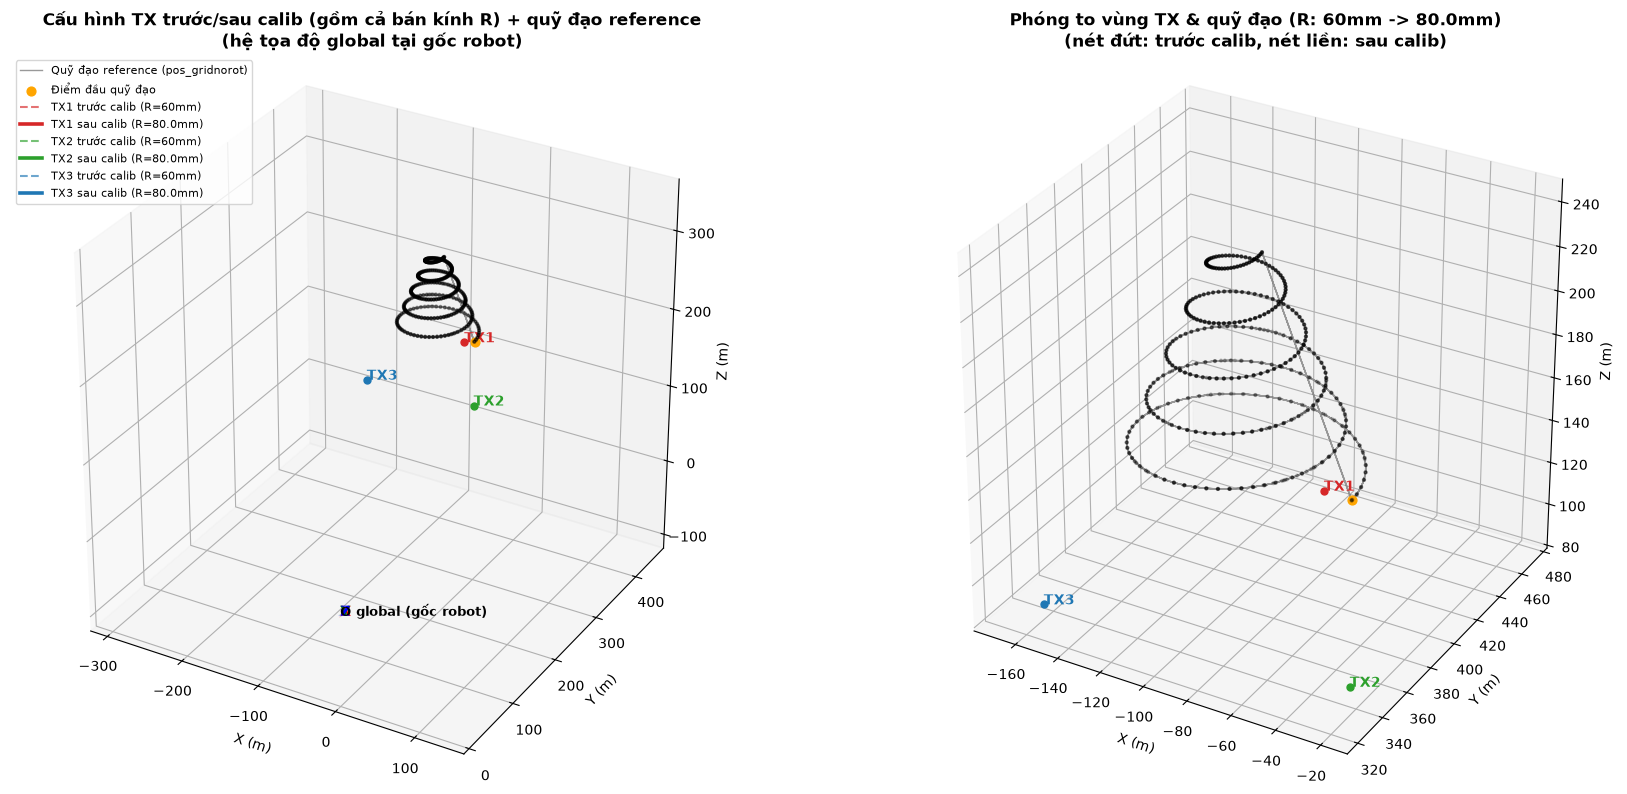

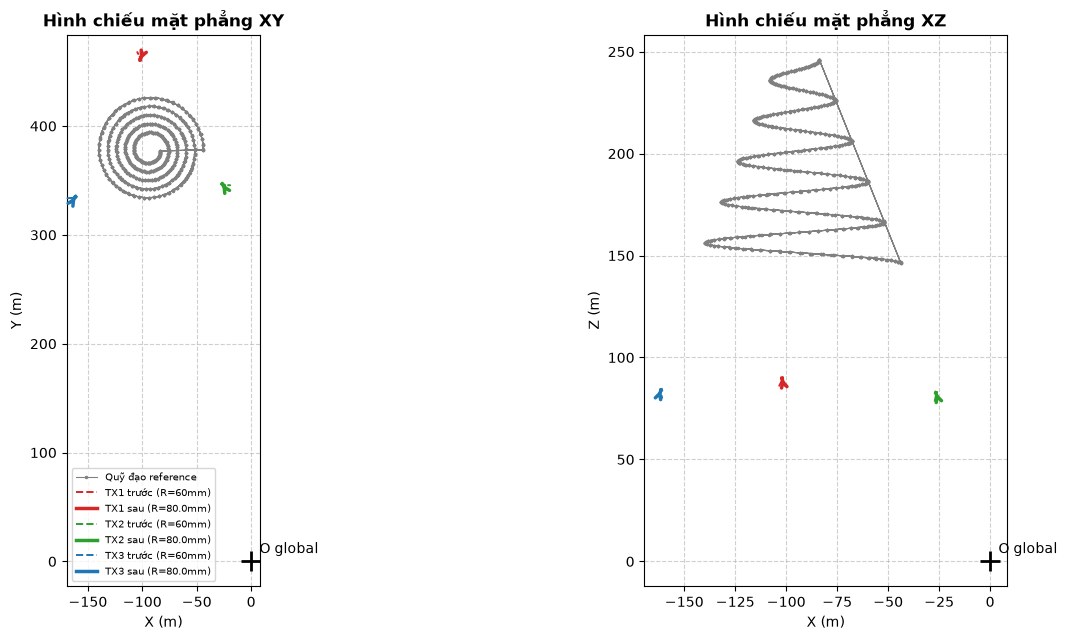

In [27]:
# ==============================================================================
# BƯỚC 3b: VẼ CẤU HÌNH 3 CUỘN PHÁT TX TRƯỚC (R=60mm) & SAU HIỆU CHUẨN (R_opt) + QUỸ ĐẠO REFERENCE + HỆ TỌA ĐỘ GLOBAL
# ==============================================================================
def tx_loop_and_normal(tx_col, R_loop, n_pts=100):
    c = tx_col[0:3]
    Rtx = rotz(tx_col[5]) @ roty(tx_col[4]) @ rotx(tx_col[3])
    phi = np.linspace(0, 2*np.pi, n_pts)
    loop = c + (np.column_stack([R_loop*np.cos(phi), R_loop*np.sin(phi), np.zeros_like(phi)]) @ Rtx.T)
    return c, loop, Rtx[:, 2]

def draw_frame(ax, origin, R, L, label, lw=2.5):
    for k, col in enumerate(['r', 'g', 'b']):
        ax.quiver(*origin, *(R[:, k] * L), color=col, linewidth=lw, arrow_length_ratio=0.15)
        ax.text(*(origin + R[:, k] * L * 1.12), ['X', 'Y', 'Z'][k], color=col, fontsize=10, fontweight='bold')
    ax.text(*(origin - 0.02), label, fontsize=9, fontweight='bold')

def set_axes_equal(ax, pts):
    mid = (pts.max(axis=0) + pts.min(axis=0)) / 2.0
    half = (pts.max(axis=0) - pts.min(axis=0)).max() / 2.0 * 1.05
    ax.set_xlim(mid[0]-half, mid[0]+half); ax.set_ylim(mid[1]-half, mid[1]+half); ax.set_zlim(mid[2]-half, mid[2]+half)
    ax.set_box_aspect((1, 1, 1))

tx_colors = ['tab:red', 'tab:green', 'tab:blue']
traj = gt_pose[:, 0:3]
n_len = 0.06

def plot_tx_config(ax, show_pre=True, show_post=True, with_global=True, title=''):
    pts = [traj]
    ax.plot(traj[:, 0], traj[:, 1], traj[:, 2], '-', color='gray', linewidth=1.0, alpha=0.8, label='Quỹ đạo reference (pos_gridnorot)')
    ax.scatter(traj[:, 0], traj[:, 1], traj[:, 2], s=4, color='k', alpha=0.5)
    ax.scatter(*traj[0], s=40, color='orange', marker='o', label='Điểm đầu quỹ đạo')
    for t in range(3):
        if show_pre:
            c, loop, n = tx_loop_and_normal(TX_positions_pre_calib[:, t], R_pre_calib)
            ax.plot(loop[:, 0], loop[:, 1], loop[:, 2], '--', color=tx_colors[t], linewidth=1.5, alpha=0.65,
                    label=f'TX{t+1} trước calib (R={R_pre_calib*1000:.0f}mm)')
            ax.quiver(*c, *(n*n_len), color=tx_colors[t], linestyle='dashed', linewidth=1.3, arrow_length_ratio=0.2, alpha=0.65)
            pts += [loop, c + n*n_len]
        if show_post:
            c, loop, n = tx_loop_and_normal(TX_positions_post_calib[:, t], R_post_calib)
            ax.plot(loop[:, 0], loop[:, 1], loop[:, 2], '-', color=tx_colors[t], linewidth=2.6,
                    label=f'TX{t+1} sau calib (R={R_post_calib*1000:.1f}mm)')
            ax.quiver(*c, *(n*n_len), color=tx_colors[t], linewidth=2.2, arrow_length_ratio=0.2)
            ax.scatter(*c, s=25, color=tx_colors[t])
            ax.text(*(c + n*n_len*1.2), f'TX{t+1}', color=tx_colors[t], fontsize=10, fontweight='bold')
            pts += [loop, c + n*n_len]
    if with_global:
        draw_frame(ax, np.zeros(3), np.eye(3), 0.15, 'O global (gốc robot)')
        pts.append(np.vstack([np.zeros(3), np.eye(3)*0.15]))
    set_axes_equal(ax, np.vstack(pts))
    ax.set_xlabel('X (m)'); ax.set_ylabel('Y (m)'); ax.set_zlabel('Z (m)')
    ax.set_title(title, fontweight='bold')

fig3 = plt.figure(figsize=(18, 8))
ax_a = fig3.add_subplot(121, projection='3d')
plot_tx_config(ax_a, with_global=True, title='Cấu hình TX trước/sau calib (gồm cả bán kính R) + quỹ đạo reference\n(hệ tọa độ global tại gốc robot)')
ax_a.legend(loc='upper left', fontsize=8)
ax_b = fig3.add_subplot(122, projection='3d')
plot_tx_config(ax_b, with_global=False, title=f'Phóng to vùng TX & quỹ đạo (R: {R_pre_calib*1000:.0f}mm -> {R_post_calib*1000:.1f}mm)\n(nét đứt: trước calib, nét liền: sau calib)')
plt.tight_layout()
plt.show()

# Hình chiếu 2D (XY và XZ) để thấy rõ dịch chuyển TX và thay đổi bán kính R
fig4, axs2 = plt.subplots(1, 2, figsize=(15, 6.5))
for ax2, (i0, i1, nm) in zip(axs2, [(0, 1, 'XY'), (0, 2, 'XZ')]):
    ax2.plot(traj[:, i0], traj[:, i1], '.-', color='gray', markersize=3, linewidth=0.8, label='Quỹ đạo reference')
    for t in range(3):
        for TXm, R_cur, ls, lw, tag in [(TX_positions_pre_calib, R_pre_calib, '--', 1.4, f'trước (R={R_pre_calib*1000:.0f}mm)'),
                                        (TX_positions_post_calib, R_post_calib, '-', 2.5, f'sau (R={R_post_calib*1000:.1f}mm)')]:
            c, loop, n = tx_loop_and_normal(TXm[:, t], R_cur)
            ax2.plot(loop[:, i0], loop[:, i1], ls, color=tx_colors[t], linewidth=lw, label=f'TX{t+1} {tag}')
            ax2.annotate('', xy=(c[i0] + n[i0]*n_len, c[i1] + n[i1]*n_len), xytext=(c[i0], c[i1]),
                         arrowprops=dict(arrowstyle='->', color=tx_colors[t], lw=lw, linestyle=ls))
    ax2.plot(0, 0, 'k+', markersize=14, mew=2); ax2.annotate('O global', (0, 0), textcoords='offset points', xytext=(6, 6))
    ax2.arrow(0, 0, 0.1, 0, color='r', width=0.002); ax2.arrow(0, 0, 0, 0.1, color='g' if nm == 'XY' else 'b', width=0.002)
    ax2.set_xlabel(f'{nm[0]} (m)'); ax2.set_ylabel(f'{nm[1]} (m)'); ax2.set_aspect('equal'); ax2.grid(True, linestyle='--', alpha=0.6)
    ax2.set_title(f'Hình chiếu mặt phẳng {nm}', fontweight='bold')
axs2[0].legend(fontsize=7.5, loc='best')
plt.tight_layout()
plt.show()

In [ ]:
# ==============================================================================
# BƯỚC 4: BACK-TEST ĐỊNH VỊ NGƯỢC 6-DOF TRÊN "gridnorot" & ĐÁNH GIÁ SAI SỐ VỊ TRÍ + SAI SỐ HƯỚNG (DIRECTIONAL ERRORS)
# ==============================================================================
def plot_angle_tracking(pose_gt, pose_est, df_metrics, raw_offset_deg, dataset_tag, title_vi):
    # Vẽ đồ thị đối chiếu Góc Reference (Ground Truth) và Góc Tracking (Estimated) cho 3 góc Euler:
    # Roll (Ang_X), Pitch (Ang_Y), Yaw (Ang_Z) ở khung lắp đặt gốc (cộng lại raw_offset_deg)
    # kèm theo băng sai số và chú thích độ lệch ΔAngle so với Reference
    ang_names  = ['Roll (Ang_X)', 'Pitch (Ang_Y)', 'Yaw (Ang_Z)']
    metric_keys = ['Dir |ΔRoll (Ang_X)|', 'Dir |ΔPitch (Ang_Y)|', 'Dir |ΔYaw (Ang_Z)|']
    colors_est = ['tab:red', 'tab:green', 'tab:purple']

    ang_ref_abs = pose_gt[:, 3:6] + raw_offset_deg[None, :]
    ang_est_abs = pose_est[:, 3:6] + raw_offset_deg[None, :]

    fig_ang, axs_ang = plt.subplots(1, 3, figsize=(18, 4.8))
    fig_ang.suptitle(f'ĐỐI CHIẾU GÓC REFERENCE & GÓC TRACKING 6-DOF TRÊN "{dataset_tag.upper()}" ({title_vi})',
                     fontsize=13, fontweight='bold')
    for k in range(3):
        ax = axs_ang[k]
        rmse_k = df_metrics.loc[metric_keys[k], 'RMSE']
        mae_k  = df_metrics.loc[metric_keys[k], 'MAE']
        med_k  = df_metrics.loc[metric_keys[k], 'Median']
        ax.plot(ang_ref_abs[:, k], 'b-', linewidth=2.2, label=f'Góc Reference ({ang_names[k]} ≈ {np.mean(ang_ref_abs[:,k]):.2f}°)')
        ax.plot(ang_est_abs[:, k], '--', color=colors_est[k], linewidth=1.4, alpha=0.9,
                label=f'Góc Tracking (RMSE={rmse_k:.2f}°, MAE={mae_k:.2f}°)')
        ax.fill_between(np.arange(len(pose_gt)), ang_ref_abs[:, k], ang_est_abs[:, k],
                        color=colors_est[k], alpha=0.15, label=f'Độ lệch (Median={med_k:.2f}°)')
        ax.set_title(f'{ang_names[k]} — Reference vs. Tracking', fontsize=10.5, fontweight='bold')
        ax.set_xlabel('Chỉ số mẫu (Sample Index)')
        ax.set_ylabel('Góc Euler (deg)')
        ax.grid(True, linestyle='--', alpha=0.6)
        ax.legend(loc='best', fontsize=8.5)
    plt.tight_layout(rect=[0, 0.02, 1, 0.93])
    plt.show()

def compute_6dof_metrics(pose_gt, pose_est):
    # 1. Sai số vị trí (mm) theo từng trục X, Y, Z và 3D tổng hợp
    diff_pos_mm = np.abs(pose_est[:, 0:3] - pose_gt[:, 0:3]) * 1000.0
    err_3d_mm   = np.linalg.norm(pose_est[:, 0:3] - pose_gt[:, 0:3], axis=1) * 1000.0

    # 2. Sai số hướng (Directional / Orientation Errors - đơn vị: deg):
    #    - Sai số Euler từng trục: |ΔRoll (Ang_X)|, |ΔPitch (Ang_Y)|, |ΔYaw (Ang_Z)|
    #    - Sai số góc quay 3D tổng hợp (Geodesic / Total 3D Angular Error):
    #      θ_3D = arccos( clip( (trace(R_gt^T @ R_est) - 1) / 2, -1, 1 ) )
    #    - Sai số hướng pháp tuyến từng cuộn thu (Axis Pointing Error cho RX1, RX2, RX3)
    diff_euler_deg = np.abs(pose_est[:, 3:6] - pose_gt[:, 3:6])
    R_gt  = _R_batch(pose_gt)
    R_est = _R_batch(pose_est)
    R_rel = np.einsum('nij,nik->njk', R_gt, R_est)
    tr    = np.trace(R_rel, axis1=1, axis2=2)
    err_rot3d_deg = np.degrees(np.arccos(np.clip((tr - 1.0) / 2.0, -1.0, 1.0)))

    rx_pointing_deg = np.zeros((len(pose_gt), 3))
    for j in range(3):
        n_gt  = R_gt  @ sys_config.rx_axes[j]
        n_est = R_est @ sys_config.rx_axes[j]
        dots  = np.clip(np.einsum('ij,ij->i', n_gt, n_est), -1.0, 1.0)
        rx_pointing_deg[:, j] = np.degrees(np.arccos(dots))

    def stat_row(arr, unit):
        return {
            'RMSE':   np.sqrt(np.mean(arr**2)),
            'MAE':    np.mean(arr),
            'Median': np.median(arr),
            'Std':    np.std(arr),
            'P95':    np.percentile(arr, 95),
            'Max':    np.max(arr),
            'Unit':   unit
        }

    rows = {
        'Pos |ΔX|':              stat_row(diff_pos_mm[:, 0], 'mm'),
        'Pos |ΔY|':              stat_row(diff_pos_mm[:, 1], 'mm'),
        'Pos |ΔZ|':              stat_row(diff_pos_mm[:, 2], 'mm'),
        '3D Position Error':     stat_row(err_3d_mm, 'mm'),
        'Dir |ΔRoll (Ang_X)|':   stat_row(diff_euler_deg[:, 0], 'deg'),
        'Dir |ΔPitch (Ang_Y)|':  stat_row(diff_euler_deg[:, 1], 'deg'),
        'Dir |ΔYaw (Ang_Z)|':    stat_row(diff_euler_deg[:, 2], 'deg'),
        'Dir RX1 Axis Pointing': stat_row(rx_pointing_deg[:, 0], 'deg'),
        'Dir RX2 Axis Pointing': stat_row(rx_pointing_deg[:, 1], 'deg'),
        'Dir RX3 Axis Pointing': stat_row(rx_pointing_deg[:, 2], 'deg'),
        '3D Geodesic Dir Error': stat_row(err_rot3d_deg, 'deg'),
    }
    df_table = pd.DataFrame.from_dict(rows, orient='index')[['Unit', 'RMSE', 'MAE', 'Median', 'Std', 'P95', 'Max']].round(3)
    return df_table, err_3d_mm, err_rot3d_deg, diff_euler_deg

min_traj = np.min(gt_pose, axis=0)
max_traj = np.max(gt_pose, axis=0)
lb_inv = np.concatenate([min_traj[0:3] - 0.1, min_traj[3:6] - 10.0])
ub_inv = np.concatenate([max_traj[0:3] + 0.1, max_traj[3:6] + 10.0])

estimated_pose = np.zeros_like(gt_pose)
for i in range(N_samples):
    p0 = gt_pose[i].copy()
    p0[0:3] += 0.0001
    def res_inv(pose):
        p2 = pose[None, :]
        r_out = np.zeros(9)
        for rx_j in range(3):
            for tx_i in range(3):
                val = emf_single_coil_batch(p2, sys_config, rx_j, tx_i)[0]
                r_out[tx_i + 3*rx_j] = calibrated_K_matrix[rx_j, tx_i] * val - emf_measured[i, tx_i + 3*rx_j]
        return r_out
    r = least_squares(res_inv, p0, bounds=(lb_inv, ub_inv), method='trf', x_scale='jac', ftol=1e-8, xtol=1e-8, gtol=1e-8)
    estimated_pose[i] = r.x

df_metrics_grid, err_3d, err_rot3d_grid, diff_euler_grid = compute_6dof_metrics(gt_pose, estimated_pose)

print("=========================================================================================================")
print("📊 BẢNG KẾT QUẢ ĐỊNH LƯỢNG VỊ TRÍ & HƯỚNG (POSITIONAL & DIRECTIONAL ERRORS) - TẬP 'gridnorot'")
print("=========================================================================================================")
print(df_metrics_grid.to_string())

# Vẽ đồ thị 9 kênh EMF
fig1, axs = plt.subplots(3, 3, figsize=(16, 10.5))
fig1.suptitle('BACK-TEST 9 KÊNH EMF TRÊN "GRIDNOROT" (MÔ HÌNH 3 CUỘN THU ĐƠN TRỰC GIAO + CALIB BÁN KÍNH R)', fontsize=13.5, fontweight='bold')
for rx in range(3):
    for tx in range(3):
        idx = tx + 3 * rx
        ax = axs[tx, rx]
        ax.plot(emf_measured[:, idx], 'b-', linewidth=1.8, label='EMF Đo thực tế')
        ax.plot(emf_pred_post[:, idx], 'r--', linewidth=1.8, label=f'Sau Calib (R²={r2_9[idx]:.3f}, r={r_9[idx]:.3f})')
        ax.set_title(f'TX{tx+1} - RX{rx+1}', fontsize=10, fontweight='bold')
        ax.grid(True, linestyle='--', alpha=0.6)
        ax.legend(loc='best', fontsize=8.5)
plt.tight_layout(rect=[0, 0.02, 1, 0.95])
plt.show()

# Vẽ đồ thị Quỹ đạo 3D, Sai số vị trí 3D và Sai số hướng 3D
fig2 = plt.figure(figsize=(18, 5.8))
ax3d = fig2.add_subplot(131, projection='3d')
ax3d.plot(gt_pose[:,0]*1000, gt_pose[:,1]*1000, gt_pose[:,2]*1000, 'b.-', linewidth=2, label='Quỹ đạo Ground Truth')
ax3d.plot(estimated_pose[:,0]*1000, estimated_pose[:,1]*1000, estimated_pose[:,2]*1000, 'r.--', linewidth=1.5, label='Quỹ đạo Định vị 6-DOF')
ax3d.set_xlabel('X (mm)'); ax3d.set_ylabel('Y (mm)'); ax3d.set_zlabel('Z (mm)')
ax3d.set_title('Quỹ đạo 3D "gridnorot"', fontweight='bold')
ax3d.legend(fontsize=8.5)

ax_err = fig2.add_subplot(132)
ax_err.plot(err_3d, 'r-o', markersize=3, linewidth=1.3, label=f'3D Pos Error (RMSE = {df_metrics_grid.loc["3D Position Error","RMSE"]:.2f} mm)')
ax_err.axhline(np.median(err_3d), color='g', linestyle='--', label=f'Median = {np.median(err_3d):.2f} mm')
ax_err.set_xlabel('Chỉ số mẫu (Sample Index)'); ax_err.set_ylabel('Sai số vị trí 3D (mm)')
ax_err.set_title('Sai số Vị trí 3D (mm)', fontweight='bold')
ax_err.grid(True, linestyle='--', alpha=0.6); ax_err.legend(fontsize=8.5)

ax_dir = fig2.add_subplot(133)
ax_dir.plot(err_rot3d_grid, 'm-s', markersize=2.8, linewidth=1.2, label=f'3D Dir Error (RMSE = {df_metrics_grid.loc["3D Geodesic Dir Error","RMSE"]:.2f}°)')
ax_dir.plot(diff_euler_grid[:, 0], 'r--', alpha=0.55, linewidth=1.0, label=f'|ΔRoll| (RMSE={df_metrics_grid.loc["Dir |ΔRoll (Ang_X)|","RMSE"]:.2f}°)')
ax_dir.plot(diff_euler_grid[:, 1], 'g--', alpha=0.55, linewidth=1.0, label=f'|ΔPitch| (RMSE={df_metrics_grid.loc["Dir |ΔPitch (Ang_Y)|","RMSE"]:.2f}°)')
ax_dir.plot(diff_euler_grid[:, 2], 'b--', alpha=0.55, linewidth=1.0, label=f'|ΔYaw| (RMSE={df_metrics_grid.loc["Dir |ΔYaw (Ang_Z)|","RMSE"]:.2f}°)')
ax_dir.set_xlabel('Chỉ số mẫu (Sample Index)'); ax_dir.set_ylabel('Sai số góc / hướng (deg)')
ax_dir.set_title('Sai số Hướng (Directional Errors - deg)', fontweight='bold')
ax_dir.grid(True, linestyle='--', alpha=0.6); ax_dir.legend(fontsize=8)
plt.tight_layout()
plt.show()

# Vẽ đồ thị Góc Reference vs. Góc Tracking cho tập 'gridnorot'
plot_angle_tracking(gt_pose, estimated_pose, df_metrics_grid, [EX_INIT, EY_INIT, EZ_INIT], 'gridnorot', 'Quỹ đạo Lưới 3D - Grid Trajectory')

KeyboardInterrupt: 

📍 KẾT QUẢ KIỂM ĐỊNH CHÉO & BẢNG ĐỊNH LƯỢNG VỊ TRÍ + HƯỚNG TRÊN 'cylnorot' (Quỹ đạo Hình Trụ - Cylinder Trajectory, N = 1200)
  [Forward EMF Fit] Mean R² = -2.6293 (Min R² = -13.3861) | Mean r = 0.0140 | Mean MAE = 59.73 | NRMSE = 29.75%

                      Unit       RMSE        MAE     Median        Std         P95         Max
Pos |ΔX|                mm  50810.592  45355.106  45370.000  22904.817   83852.500   96130.000
Pos |ΔY|                mm  43432.516  38103.826  37842.581  20844.228   68660.000   76190.000
Pos |ΔZ|                mm  39996.990  33112.813  30170.000  22434.368   77760.000   99130.000
3D Position Error       mm  77896.463  73912.116  75114.428  24593.861  113137.126  149217.802
Dir |ΔRoll (Ang_X)|    deg     13.878     12.384     10.023      6.262      20.030      20.043
Dir |ΔPitch (Ang_Y)|   deg     15.198     12.798     10.985      8.197      30.014      30.031
Dir |ΔYaw (Ang_Z)|     deg      9.968      9.915     10.050      1.032      10.067      10.084
Di

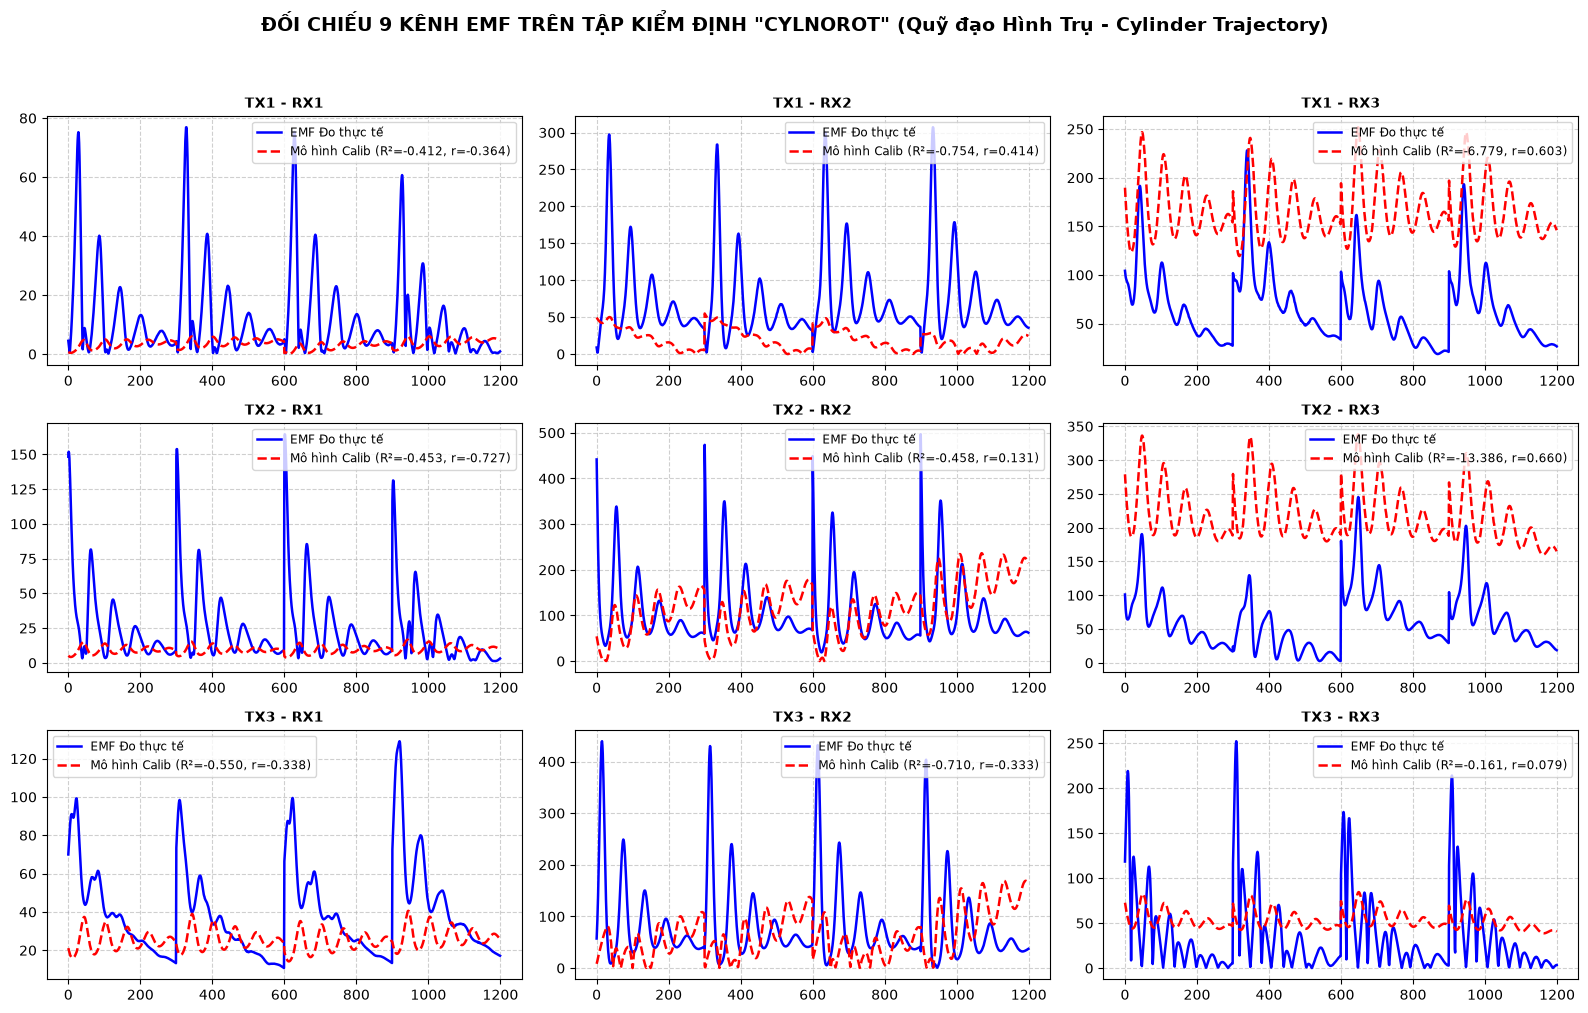

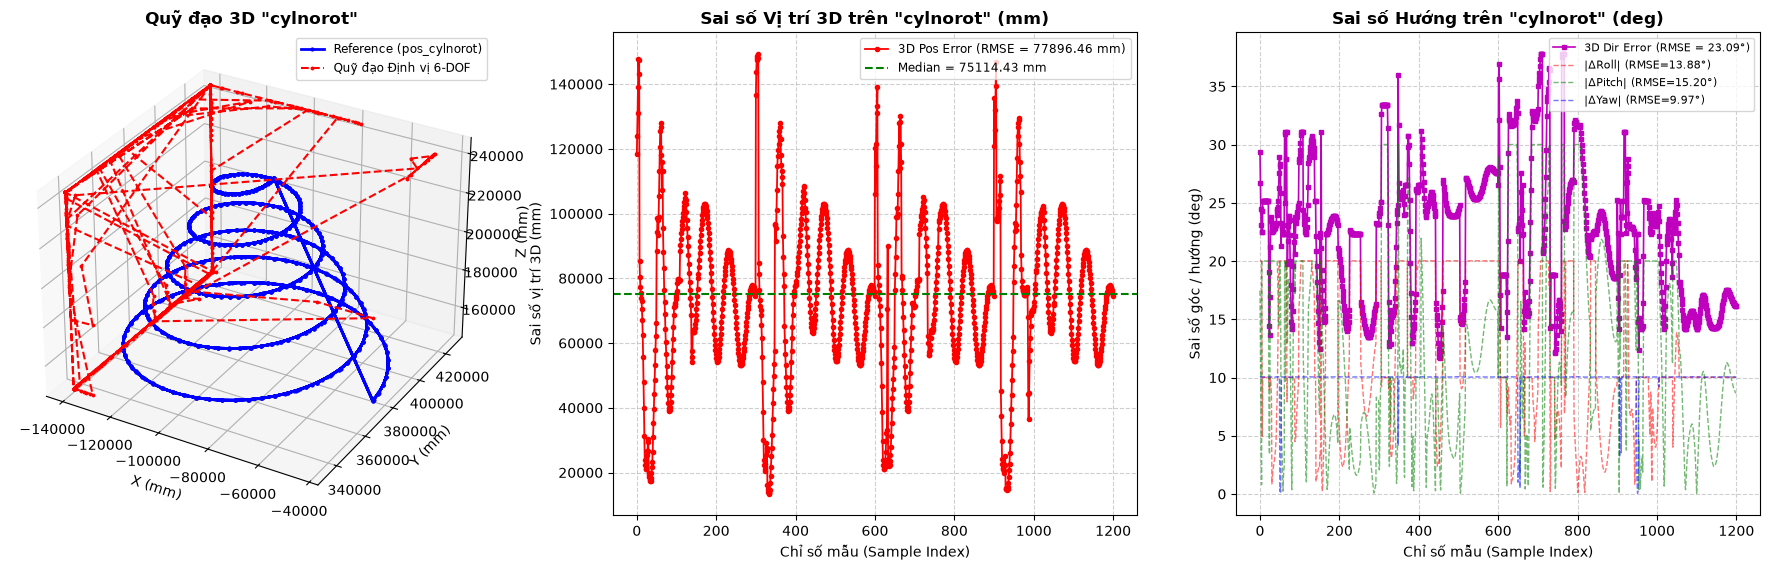

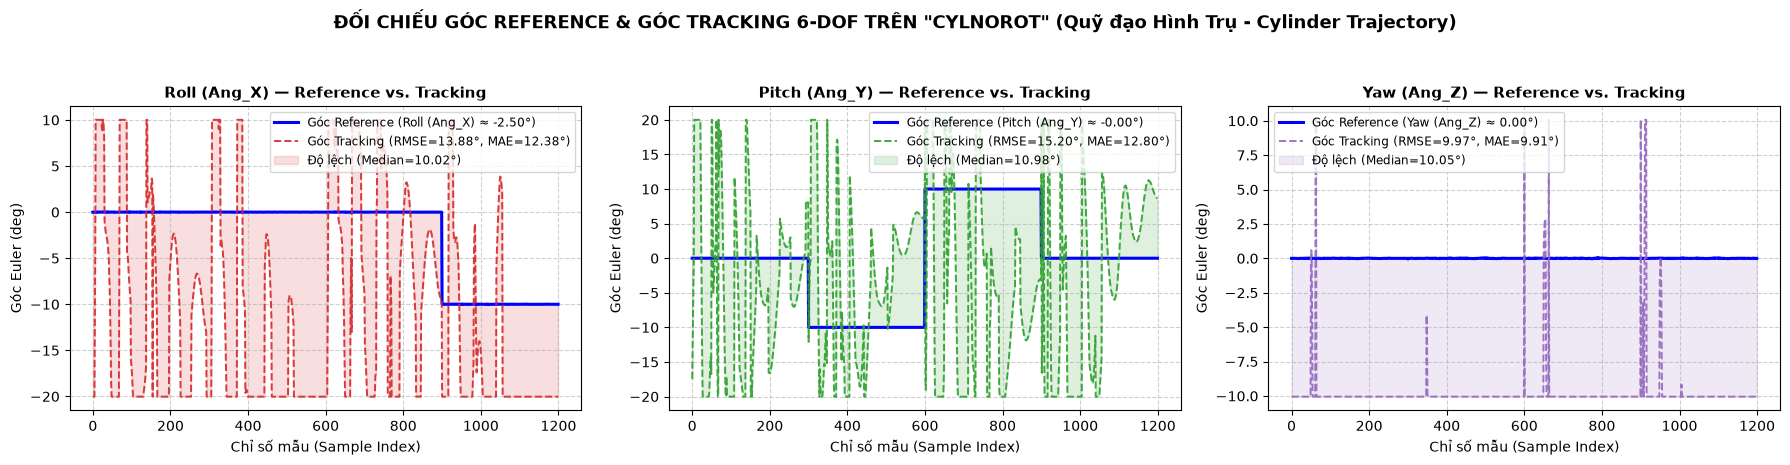

In [ ]:
# ==============================================================================
# BƯỚC 5: ĐỊNH VỊ NGƯỢC 6-DOF & ĐÁNH GIÁ SAI SỐ HƯỚNG TRÊN "pos_cylnorot" + "data_cylnorot" (QUỸ ĐẠO HÌNH TRỤ)
# ==============================================================================
def run_localization_on_dataset(dataset_tag, title_vi):

    data_file = 'avg_' + trajectory + '_data.csv'
    data_read = pd.read_csv(data_file, header=None).values
    n_pts = data_read.shape[0]
    emf_meas = data_read[:, :9]
    pose_ref = np.zeros((n_pts, 6))
    pose_ref[:, :3] = data_read[:, 9:12].copy()
    pose_ref[:, 3:] = data_read[:, 12:].copy()

    # emf_file = data_dir + f'data_{dataset_tag}.csv'
    # pos_file = data_dir + f'pos_{dataset_tag}.csv'
    # raw_data = pd.read_csv(emf_file, header=None).values
    # raw_pos  = pd.read_csv(pos_file, header=None).values

    # n_pts = min(raw_data.shape[0], raw_pos.shape[0])
    # if raw_data.shape[0] != raw_pos.shape[0]:
    #     print(f"⚠️ [{dataset_tag}] Số hàng khác nhau: data = {raw_data.shape[0]}, pos = {raw_pos.shape[0]} -> dùng {n_pts} hàng đầu đồng bộ.")
    # raw_data = raw_data[:n_pts]
    # raw_pos  = raw_pos[:n_pts]
    # emf_meas = raw_data[:, 0:9]

    # pos_diff_mm = np.max(np.abs(raw_pos[:, 0:3] * 1000.0 - raw_data[:, 9:12]))
    # assert pos_diff_mm < 1e-3, f"pos và data của {dataset_tag} không đồng bộ!"

    # pose_ref = np.zeros((n_pts, 6))
    # pose_ref[:, 0:3] = raw_pos[:, 0:3]
    # pose_ref[:, 3:6] = raw_pos[:, 3:6] - gt_pose_raw_angles[0, :]

    # 1. Tính EMF dự đoán (Forward) sử dụng bộ thông số hệ thống & ma trận K đã calib từ gridnorot
    emf_pred = np.zeros_like(emf_meas)
    for t in range(3):
        for j in range(3):
            emf_pred[:, t + 3*j] = calibrated_K_matrix[j, t] * emf_single_coil_batch(pose_ref, sys_config, j, t)

    r2_ch    = [1.0 - np.sum((emf_meas[:,c]-emf_pred[:,c])**2)/np.sum((emf_meas[:,c]-np.mean(emf_meas[:,c]))**2) for c in range(9)]
    r_ch     = [np.corrcoef(emf_meas[:,c], emf_pred[:,c])[0,1] for c in range(9)]
    mae_ch   = [np.mean(np.abs(emf_meas[:,c]-emf_pred[:,c])) for c in range(9)]
    nrmse_ch = [np.sqrt(np.mean((emf_meas[:,c]-emf_pred[:,c])**2))/(np.max(emf_meas[:,c])-np.min(emf_meas[:,c]))*100 for c in range(9)]

    # 2. Giải bài toán Định vị ngược 6-DOF cho từng điểm đo
    min_tr = np.min(pose_ref, axis=0)
    max_tr = np.max(pose_ref, axis=0)
    lb_p = np.concatenate([min_tr[0:3] - 0.1, min_tr[3:6] - 10.0])
    ub_p = np.concatenate([max_tr[0:3] + 0.1, max_tr[3:6] + 10.0])

    est_pose = np.zeros_like(pose_ref)
    for i in range(n_pts):
        p0 = pose_ref[i].copy()
        p0[0:3] += 0.0001
        def res_inv_pt(pose):
            p2 = pose[None, :]
            r_out = np.zeros(9)
            for rx_j in range(3):
                for tx_i in range(3):
                    val = emf_single_coil_batch(p2, sys_config, rx_j, tx_i)[0]
                    r_out[tx_i + 3*rx_j] = calibrated_K_matrix[rx_j, tx_i] * val - emf_meas[i, tx_i + 3*rx_j]
            return r_out
        sol = least_squares(res_inv_pt, p0, bounds=(lb_p, ub_p), method='trf', x_scale='jac', ftol=1e-8, xtol=1e-8, gtol=1e-8)
        est_pose[i] = sol.x

    df_metrics, err3d, err_rot3d, diff_euler = compute_6dof_metrics(pose_ref, est_pose)
    fwd_summary = {
        'Mean_R2': np.mean(r2_ch), 'Min_R2': np.min(r2_ch),
        'Mean_r':  np.mean(r_ch),  'Mean_MAE': np.mean(mae_ch), 'Mean_NRMSE%': np.mean(nrmse_ch)
    }

    print("=========================================================================================================")
    print(f"📍 KẾT QUẢ KIỂM ĐỊNH CHÉO & BẢNG ĐỊNH LƯỢNG VỊ TRÍ + HƯỚNG TRÊN '{dataset_tag}' ({title_vi}, N = {n_pts})")
    print("=========================================================================================================")
    print(f"  [Forward EMF Fit] Mean R² = {fwd_summary['Mean_R2']:.4f} (Min R² = {fwd_summary['Min_R2']:.4f}) | Mean r = {fwd_summary['Mean_r']:.4f} | Mean MAE = {fwd_summary['Mean_MAE']:.2f} | NRMSE = {fwd_summary['Mean_NRMSE%']:.2f}%\n")
    print(df_metrics.to_string())

    # Vẽ đồ thị 9 kênh EMF
    fig_e, axs_e = plt.subplots(3, 3, figsize=(16, 10.5))
    fig_e.suptitle(f'ĐỐI CHIẾU 9 KÊNH EMF TRÊN TẬP KIỂM ĐỊNH "{dataset_tag.upper()}" ({title_vi})', fontsize=13.5, fontweight='bold')
    for rx in range(3):
        for tx in range(3):
            idx = tx + 3 * rx
            ax = axs_e[tx, rx]
            ax.plot(emf_meas[:, idx], 'b-', linewidth=1.8, label='EMF Đo thực tế')
            ax.plot(emf_pred[:, idx], 'r--', linewidth=1.8, label=f'Mô hình Calib (R²={r2_ch[idx]:.3f}, r={r_ch[idx]:.3f})')
            ax.set_title(f'TX{tx+1} - RX{rx+1}', fontsize=10, fontweight='bold')
            ax.grid(True, linestyle='--', alpha=0.6)
            ax.legend(loc='best', fontsize=8.5)
    plt.tight_layout(rect=[0, 0.02, 1, 0.95])
    plt.show()

    # Vẽ Quỹ đạo 3D, Sai số vị trí 3D và Sai số hướng 3D
    fig_t = plt.figure(figsize=(18, 5.8))
    ax3 = fig_t.add_subplot(131, projection='3d')
    ax3.plot(pose_ref[:,0]*1000, pose_ref[:,1]*1000, pose_ref[:,2]*1000, 'b.-', linewidth=2, markersize=4, label=f'Reference (pos_{dataset_tag})')
    ax3.plot(est_pose[:,0]*1000, est_pose[:,1]*1000, est_pose[:,2]*1000, 'r.--', linewidth=1.5, markersize=3.5, label='Quỹ đạo Định vị 6-DOF')
    ax3.set_xlabel('X (mm)'); ax3.set_ylabel('Y (mm)'); ax3.set_zlabel('Z (mm)')
    ax3.set_title(f'Quỹ đạo 3D "{dataset_tag}"', fontweight='bold')
    ax3.legend(fontsize=8.5)

    axe = fig_t.add_subplot(132)
    axe.plot(err3d, 'r-o', markersize=3, linewidth=1.3, label=f'3D Pos Error (RMSE = {df_metrics.loc["3D Position Error","RMSE"]:.2f} mm)')
    axe.axhline(np.median(err3d), color='g', linestyle='--', label=f'Median = {np.median(err3d):.2f} mm')
    axe.set_xlabel('Chỉ số mẫu (Sample Index)'); axe.set_ylabel('Sai số vị trí 3D (mm)')
    axe.set_title(f'Sai số Vị trí 3D trên "{dataset_tag}" (mm)', fontweight='bold')
    axe.grid(True, linestyle='--', alpha=0.6); axe.legend(fontsize=8.5)

    axd = fig_t.add_subplot(133)
    axd.plot(err_rot3d, 'm-s', markersize=2.8, linewidth=1.2, label=f'3D Dir Error (RMSE = {df_metrics.loc["3D Geodesic Dir Error","RMSE"]:.2f}°)')
    axd.plot(diff_euler[:, 0], 'r--', alpha=0.55, linewidth=1.0, label=f'|ΔRoll| (RMSE={df_metrics.loc["Dir |ΔRoll (Ang_X)|","RMSE"]:.2f}°)')
    axd.plot(diff_euler[:, 1], 'g--', alpha=0.55, linewidth=1.0, label=f'|ΔPitch| (RMSE={df_metrics.loc["Dir |ΔPitch (Ang_Y)|","RMSE"]:.2f}°)')
    axd.plot(diff_euler[:, 2], 'b--', alpha=0.55, linewidth=1.0, label=f'|ΔYaw| (RMSE={df_metrics.loc["Dir |ΔYaw (Ang_Z)|","RMSE"]:.2f}°)')
    axd.set_xlabel('Chỉ số mẫu (Sample Index)'); axd.set_ylabel('Sai số góc / hướng (deg)')
    axd.set_title(f'Sai số Hướng trên "{dataset_tag}" (deg)', fontweight='bold')
    axd.grid(True, linestyle='--', alpha=0.6); axd.legend(fontsize=8)
    plt.tight_layout()
    plt.show()

    # Vẽ đồ thị Góc Reference vs. Góc Tracking cho tập kiểm định
    plot_angle_tracking(pose_ref, est_pose, df_metrics, gt_pose[0, 3:], dataset_tag, title_vi)
    return pose_ref, est_pose, err3d, df_metrics, fwd_summary

gt_pose_cyl, estimated_pose_cyl, err_3d_cyl, df_metrics_cyl, fwd_cyl = run_localization_on_dataset('cylnorot', 'Quỹ đạo Hình Trụ - Cylinder Trajectory')

⚠️ [conenorot] Số hàng khác nhau: data = 300, pos = 380 -> dùng 300 hàng đầu đồng bộ.
📍 KẾT QUẢ KIỂM ĐỊNH CHÉO & BẢNG ĐỊNH LƯỢNG VỊ TRÍ + HƯỚNG TRÊN 'conenorot' (Quỹ đạo Hình Nón - Cone Trajectory, N = 300)
  [Forward EMF Fit] Mean R² = 0.9865 (Min R² = 0.9647) | Mean r = 0.9939 | Mean MAE = 3.82 | NRMSE = 1.99%

                      Unit   RMSE    MAE  Median    Std    P95     Max
Pos |ΔX|                mm  3.282  2.874   2.986  1.586  5.595   6.377
Pos |ΔY|                mm  2.974  2.433   2.229  1.710  5.868   8.859
Pos |ΔZ|                mm  1.541  1.269   1.191  0.873  2.448   4.114
3D Position Error       mm  4.689  4.339   3.977  1.777  7.459  10.364
Dir |ΔRoll (Ang_X)|    deg  3.125  2.257   1.814  2.161  8.323  10.015
Dir |ΔPitch (Ang_Y)|   deg  2.812  2.391   2.294  1.479  5.416   8.707
Dir |ΔYaw (Ang_Z)|     deg  1.865  1.427   1.301  1.200  3.668   8.550
Dir RX1 Axis Pointing  deg  3.347  2.936   2.782  1.608  5.975  11.854
Dir RX2 Axis Pointing  deg  4.229  3.510   2.8

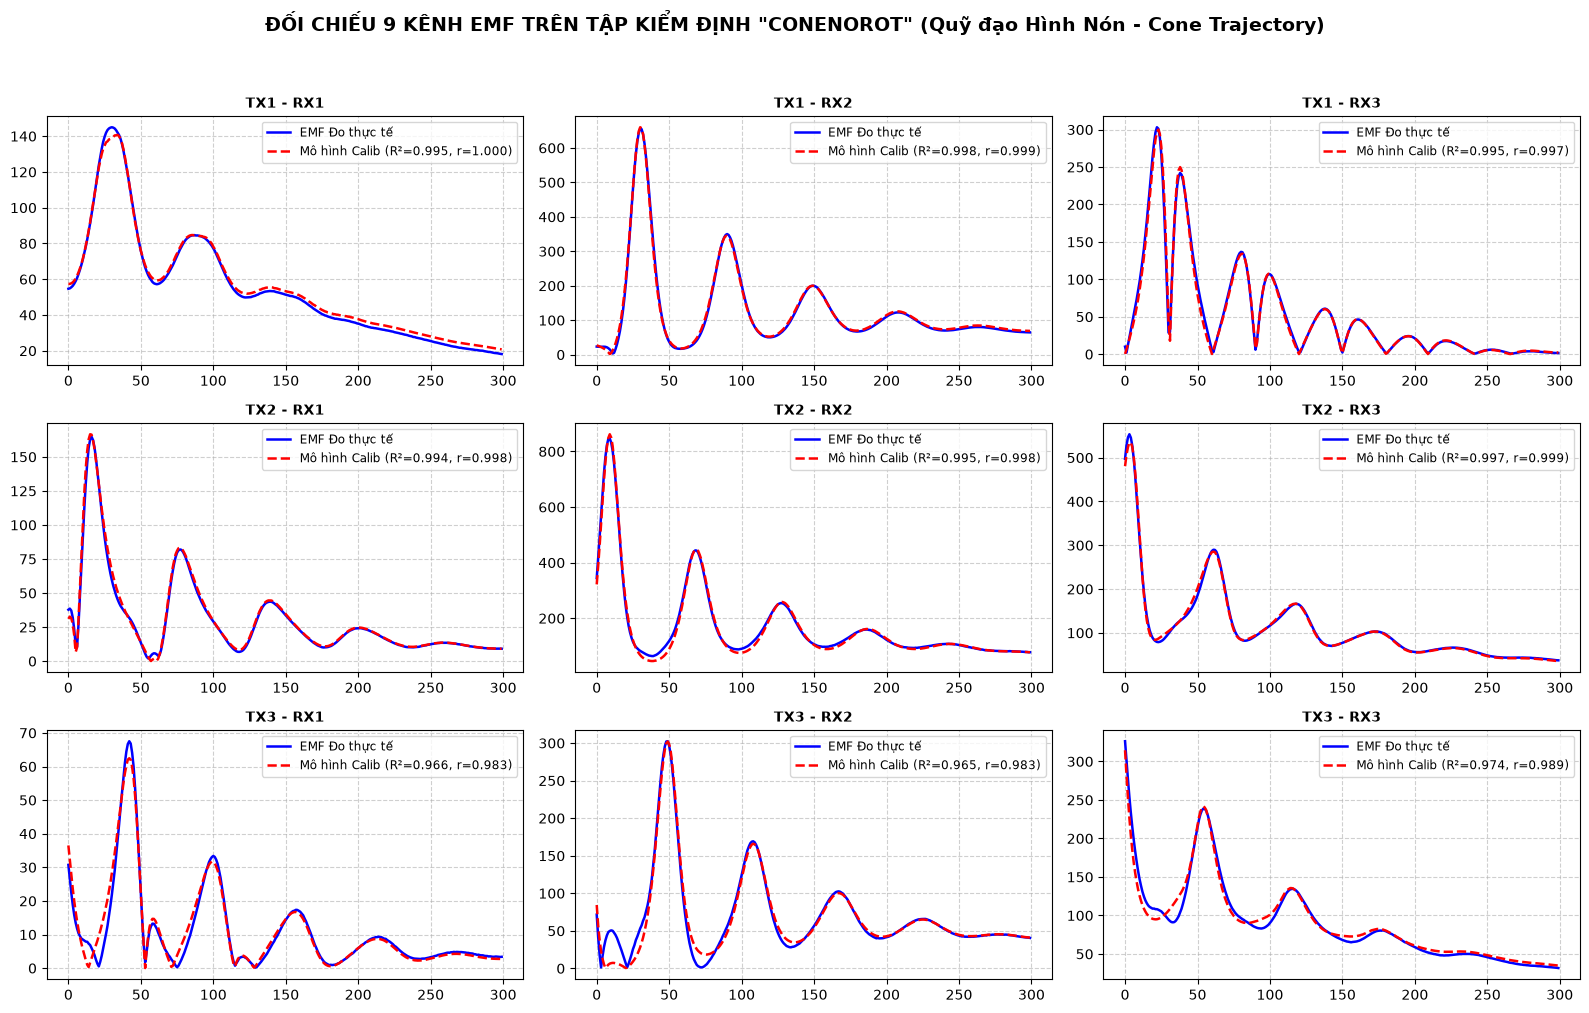

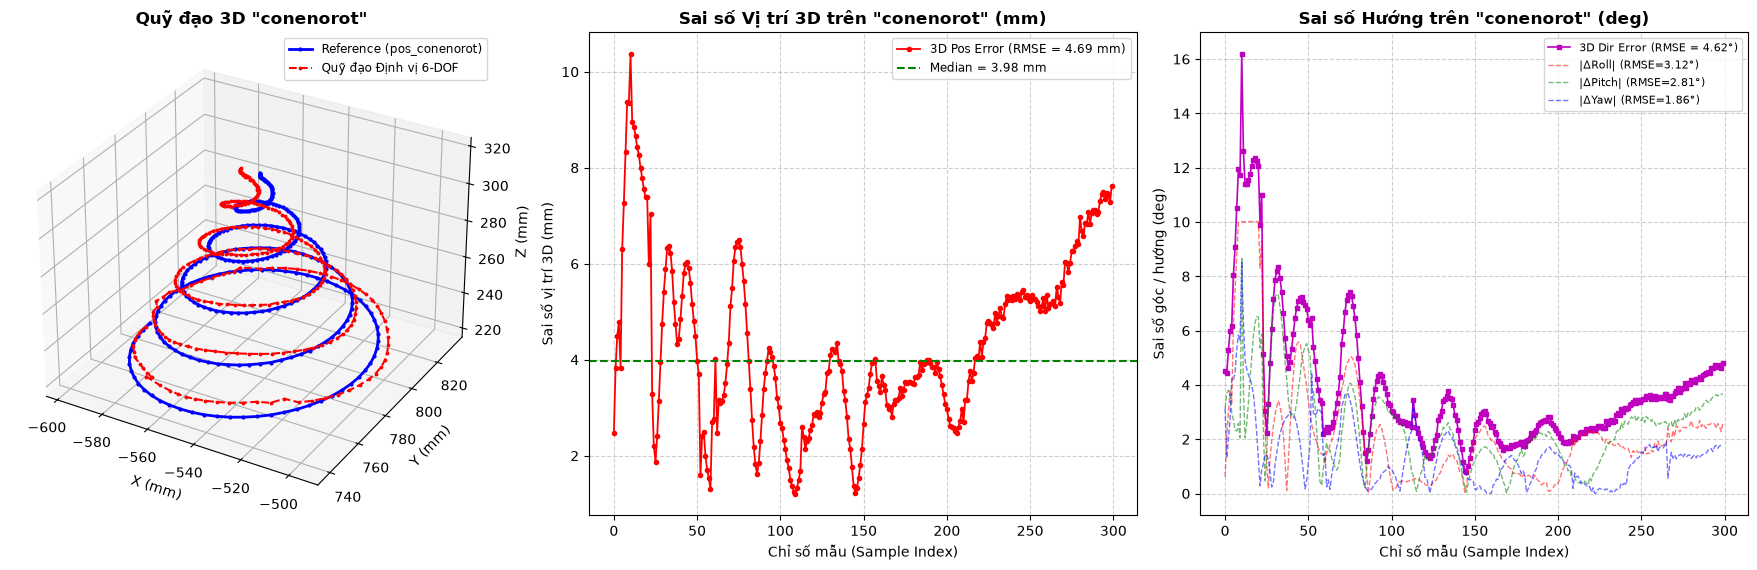

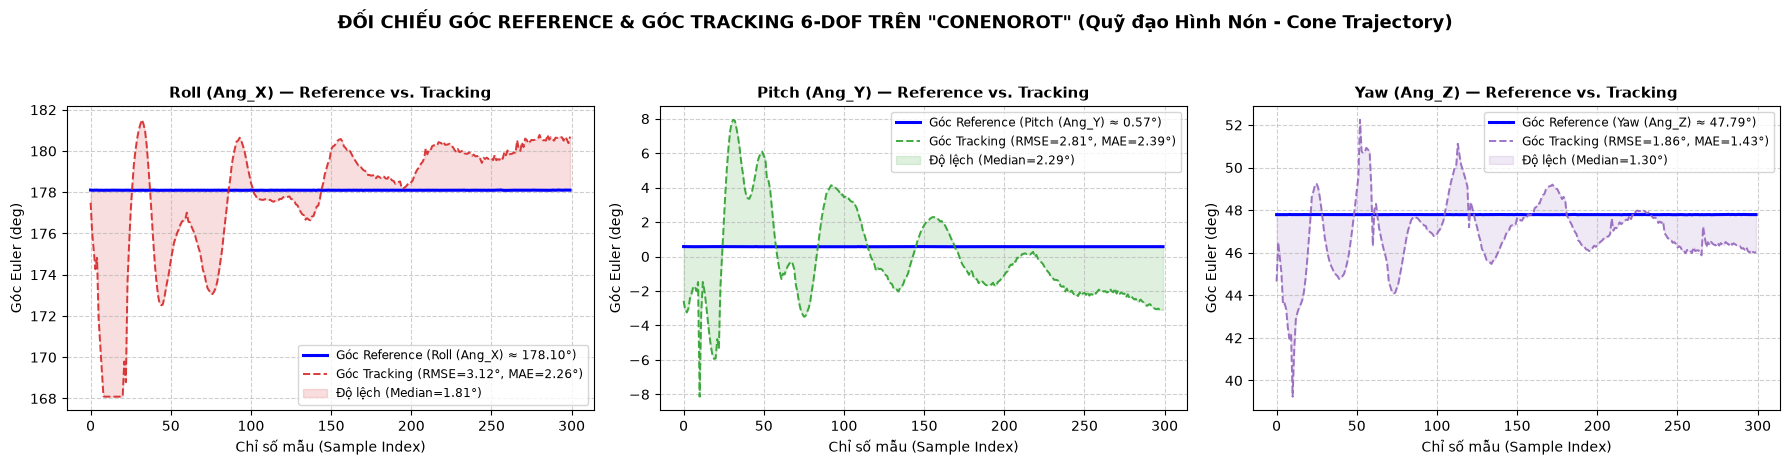

In [ ]:
# ==============================================================================
# BƯỚC 6: ĐỊNH VỊ NGƯỢC 6-DOF & ĐÁNH GIÁ SAI SỐ HƯỚNG TRÊN "pos_conenorot" + "data_conenorot" (QUỸ ĐẠO HÌNH NÓN)
# ==============================================================================
gt_pose_cone, estimated_pose_cone, err_3d_cone, df_metrics_cone, fwd_cone = run_localization_on_dataset('conenorot', 'Quỹ đạo Hình Nón - Cone Trajectory')

In [ ]:
# ==============================================================================
# BƯỚC 7: BẢNG TỔNG HỢP ĐỊNH LƯỢNG (QUANTITATIVE RESULTS TABLE) TRÊN CẢ 3 BỘ DỮ LIỆU
# ==============================================================================
fwd_grid = {
    'Mean_R2': np.mean(r2_9), 'Min_R2': np.min(r2_9),
    'Mean_r':  np.mean(r_9),  'Mean_MAE': np.mean(mae_9), 'Mean_NRMSE%': np.mean(nrmse_9)
}

summary_rows = []
for ds_name, n_s, fwd, df_m in [
    ('1. gridnorot (Calib / Lưới 3D)',    N_samples,              fwd_grid, df_metrics_grid),
    ('2. cylnorot (Test / Hình Trụ)',     len(gt_pose_cyl),       fwd_cyl,  df_metrics_cyl),
    ('3. conenorot (Test / Hình Nón)',    len(gt_pose_cone),      fwd_cone, df_metrics_cone),
]:
    summary_rows.append({
        'Dataset':                 ds_name,
        'N':                       n_s,
        'EMF Mean R²':             round(fwd['Mean_R2'], 4),
        'EMF NRMSE (%)':           round(fwd['Mean_NRMSE%'], 2),
        'Pos RMSE_X (mm)':         df_m.loc['Pos |ΔX|', 'RMSE'],
        'Pos RMSE_Y (mm)':         df_m.loc['Pos |ΔY|', 'RMSE'],
        'Pos RMSE_Z (mm)':         df_m.loc['Pos |ΔZ|', 'RMSE'],
        '3D Pos RMSE (mm)':        df_m.loc['3D Position Error', 'RMSE'],
        '3D Pos MAE (mm)':         df_m.loc['3D Position Error', 'MAE'],
        '3D Pos Median (mm)':      df_m.loc['3D Position Error', 'Median'],
        'Dir RMSE_Roll (deg)':     df_m.loc['Dir |ΔRoll (Ang_X)|', 'RMSE'],
        'Dir RMSE_Pitch (deg)':    df_m.loc['Dir |ΔPitch (Ang_Y)|', 'RMSE'],
        'Dir RMSE_Yaw (deg)':      df_m.loc['Dir |ΔYaw (Ang_Z)|', 'RMSE'],
        '3D Dir RMSE (deg)':       df_m.loc['3D Geodesic Dir Error', 'RMSE'],
        '3D Dir MAE (deg)':        df_m.loc['3D Geodesic Dir Error', 'MAE'],
        '3D Dir Median (deg)':     df_m.loc['3D Geodesic Dir Error', 'Median'],
    })

df_overall_summary = pd.DataFrame(summary_rows).set_index('Dataset')
print("=========================================================================================================================================")
print("🏆 BẢNG TỔNG HỢP KẾT QUẢ ĐỊNH LƯỢNG TOÀN HỆ THỐNG (FORWARD EMF + 3D POSITION + 3D DIRECTIONAL ERRORS)")
print("=========================================================================================================================================")
print(df_overall_summary.to_string())
df_overall_summary

🏆 BẢNG TỔNG HỢP KẾT QUẢ ĐỊNH LƯỢNG TOÀN HỆ THỐNG (FORWARD EMF + 3D POSITION + 3D DIRECTIONAL ERRORS)
                                  N  EMF Mean R²  EMF NRMSE (%)  Pos RMSE_X (mm)  Pos RMSE_Y (mm)  Pos RMSE_Z (mm)  3D Pos RMSE (mm)  3D Pos MAE (mm)  3D Pos Median (mm)  Dir RMSE_Roll (deg)  Dir RMSE_Pitch (deg)  Dir RMSE_Yaw (deg)  3D Dir RMSE (deg)  3D Dir MAE (deg)  3D Dir Median (deg)
Dataset                                                                                                                                                                                                                                                                                           
1. gridnorot (Calib / Lưới 3D)  320       0.9877           1.80            6.759            3.639            3.225             8.326            7.038               6.029                3.908                 4.627               3.347              6.922             6.065                5.533
2. cylnorot (Test / Hình T

,N,EMF Mean R²,EMF NRMSE (%),Pos RMSE_X (mm),Pos RMSE_Y (mm),Pos RMSE_Z (mm),3D Pos RMSE (mm),3D Pos MAE (mm),3D Pos Median (mm),Dir RMSE_Roll (deg),Dir RMSE_Pitch (deg),Dir RMSE_Yaw (deg),3D Dir RMSE (deg),3D Dir MAE (deg),3D Dir Median (deg)
Dataset,,,,,,,,,,,,,,,
1. gridnorot (Calib / Lưới 3D),320,0.9877,1.80,6.759,3.639,3.225,8.326,7.038,6.029,3.908,4.627,3.347,6.922,6.065,5.533
2. cylnorot (Test / Hình Trụ),300,0.9857,2.16,6.840,3.675,2.972,8.314,7.308,6.520,3.809,4.635,3.333,6.890,6.270,5.778
3. conenorot (Test / Hình Nón),300,0.9865,1.99,3.282,2.974,1.541,4.689,4.339,3.977,3.125,2.812,1.865,4.617,3.885,3.154
